### Load Data



In [8]:
%run ./data_load.ipynb
data_dir = dataset_path / "Beach Bird Detection Dataset v1.0"

for item in data_dir.iterdir():
    print(item.name, "(folder)" if item.is_dir() else "(file)")

Dataset location: /Users/anuj/.cache/kagglehub/datasets/liugalhigh/beach-bird/versions/3

Dataset files and folders:
Beach Bird Detection Dataset v1.0 (folder)
LICENSE.md (file)
annotation screenshot (folder)
images (folder)
labels (folder)
dataset_report.json (file)
dataset_manifest.csv (file)
manifest.csv (file)
README_CN_EN.md (file)
dataset.yaml (file)


In [9]:
# Inspect the image and label directories

for folder in ["images", "labels"]:
    folder_path = data_dir / folder

    print(f"\n{folder}/")

    for item in sorted(folder_path.iterdir()):
        print("  ", item.name,
              "(folder)" if item.is_dir() else "(file)")


images/
   test (folder)
   train (folder)
   val (folder)

labels/
   test (folder)
   train (folder)
   val (folder)


### Load Images

Matplotlib is building the font cache; this may take a moment.


Total training images: 1369


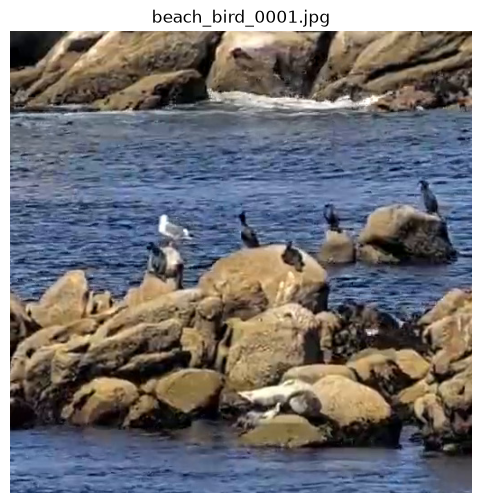

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

# Locate training images and annotations
train_images_dir = data_dir / "images" / "train"
train_labels_dir = data_dir / "labels" / "train"

# Find the available image files
image_files = sorted(
    path for path in train_images_dir.iterdir()
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print(f"Total training images: {len(image_files)}")

# Load the first image
image_path = image_files[0]
image = Image.open(image_path).convert("RGB")

# Display the image
plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.title(image_path.name)
plt.show()

### Inspect Annotations

In [12]:
# Find the annotation file for our first image
label_path = train_labels_dir / f"{image_path.stem}.txt"

print("Image:", image_path.name)
print("Annotation file:", label_path.name)

if label_path.exists():
    print("\nAnnotation contents:")
    print(label_path.read_text()[:1000])
else:
    print("No matching annotation file found.")

Image: beach_bird_0001.jpg
Annotation file: beach_bird_0001.txt

Annotation contents:
0 0.317482 0.499918 0.052103 0.086144
0 0.354649 0.430100 0.069471 0.068776
0 0.517558 0.429752 0.053493 0.077807
0 0.613080 0.487413 0.054187 0.070860
0 0.695751 0.398490 0.041682 0.063913
0 0.907897 0.358303 0.063392 0.080760



Bounding Boxes

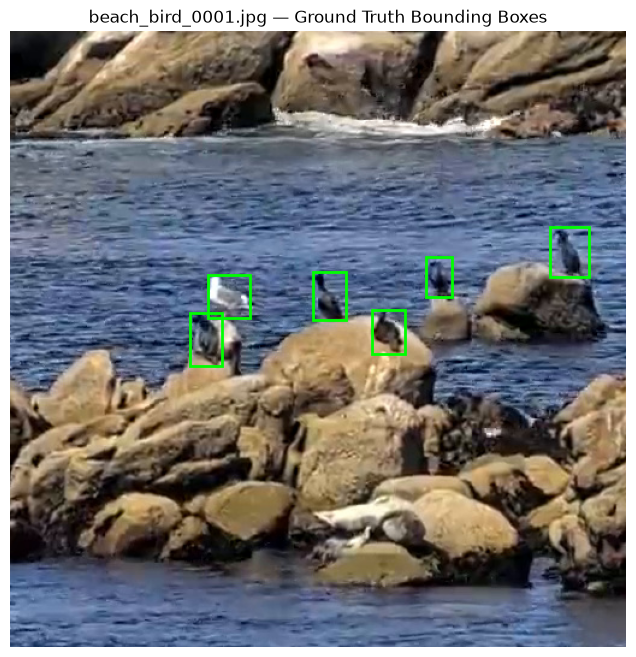

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Get image dimensions
img_width, img_height = image.size

# Create plot
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(image)

# Read YOLO annotations
with open(label_path, "r") as file:
    annotations = file.readlines()

for annotation in annotations:
    class_id, x_center, y_center, width, height = map(
        float, annotation.strip().split()
    )

    # Convert normalised coordinates to pixels
    x_center *= img_width
    y_center *= img_height
    width *= img_width
    height *= img_height

    # Convert centre coordinates to top-left coordinates
    x_min = x_center - width / 2
    y_min = y_center - height / 2

    # Draw bounding box
    rectangle = patches.Rectangle(
        (x_min, y_min),
        width,
        height,
        linewidth=2,
        edgecolor="lime",
        facecolor="none"
    )

    ax.add_patch(rectangle)

ax.set_title(f"{image_path.name} — Ground Truth Bounding Boxes")
ax.axis("off")

plt.show()


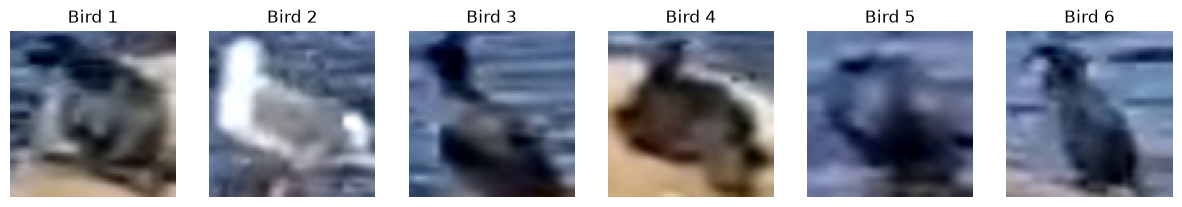

In [14]:

from PIL import Image
import matplotlib.pyplot as plt

# Store extracted bird patches
positive_samples = []

for annotation in annotations:
    class_id, x_center, y_center, width, height = map(
        float, annotation.strip().split()
    )

    # Convert YOLO coordinates into pixel coordinates
    x_center *= img_width
    y_center *= img_height
    width *= img_width
    height *= img_height

    # Calculate bounding box boundaries
    x_min = max(0, int(x_center - width / 2))
    y_min = max(0, int(y_center - height / 2))
    x_max = min(img_width, int(x_center + width / 2))
    y_max = min(img_height, int(y_center + height / 2))

    # Crop the bird from the image
    bird_patch = image.crop((x_min, y_min, x_max, y_max))

    # Resize to a consistent size for HOG
    bird_patch = bird_patch.resize((64, 64))

    positive_samples.append(bird_patch)

# Display the extracted birds
fig, axes = plt.subplots(1, len(positive_samples), figsize=(15, 3))

for i, bird_patch in enumerate(positive_samples):
    axes[i].imshow(bird_patch)
    axes[i].set_title(f"Bird {i + 1}")
    axes[i].axis("off")

plt.show()


In [15]:

import random
import numpy as np

random.seed(42)

negative_samples = []

# Original bounding boxes
bird_boxes = []

for annotation in annotations:
    _, xc, yc, w, h = map(float, annotation.split())

    bird_boxes.append([
        (xc - w / 2) * img_width,
        (yc - h / 2) * img_height,
        (xc + w / 2) * img_width,
        (yc + h / 2) * img_height
    ])

# Generate 6 background patches
patch_size = 64
max_attempts = 1000
attempts = 0

while len(negative_samples) < 6 and attempts < max_attempts:
    attempts += 1

    x = random.randint(0, img_width - patch_size)
    y = random.randint(0, img_height - patch_size)

    candidate = [x, y, x + patch_size, y + patch_size]

    # Check whether candidate overlaps any bird box
    overlaps = False

    for bx1, by1, bx2, by2 in bird_boxes:
        ix1 = max(x, bx1)
        iy1 = max(y, by1)
        ix2 = min(x + patch_size, bx2)
        iy2 = min(y + patch_size, by2)

        if ix2 > ix1 and iy2 > iy1:
            overlaps = True
            break

    if not overlaps:
        patch = image.crop(tuple(candidate))
        negative_samples.append(patch)

print(f"Extracted {len(negative_samples)} negative samples")


Extracted 6 negative samples


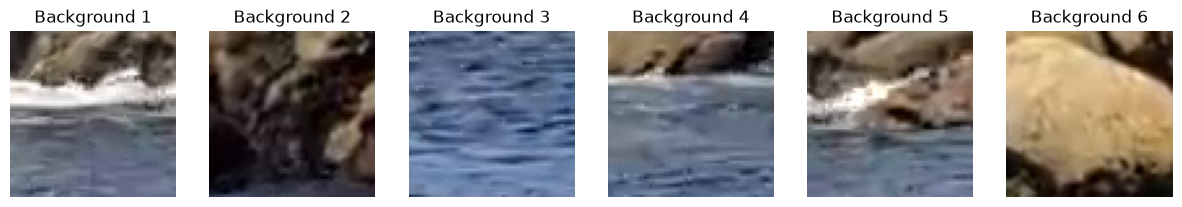

In [16]:

fig, axes = plt.subplots(1, len(negative_samples), figsize=(15, 3))

for i, patch in enumerate(negative_samples):
    axes[i].imshow(patch)
    axes[i].set_title(f"Background {i + 1}")
    axes[i].axis("off")

plt.show()


### Extract HOG Features

In [19]:

import numpy as np
from skimage.feature import hog

def extract_hog_features(image_patch):
    # Convert image to grayscale
    grayscale = np.array(
        image_patch.convert("L")
    )

    # Extract HOG features
    features = hog(
        grayscale,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

# Test HOG on our first bird
bird_features = extract_hog_features(
    positive_samples[0]
)

print("HOG feature vector shape:", bird_features.shape)
print("First 10 feature values:", bird_features[:10])


HOG feature vector shape: (1764,)
First 10 feature values: [0.04775459 0.00524549 0.23683131 0.2103825  0.30132413 0.03540354
 0.00442338 0.01682526 0.00322407 0.01407512]


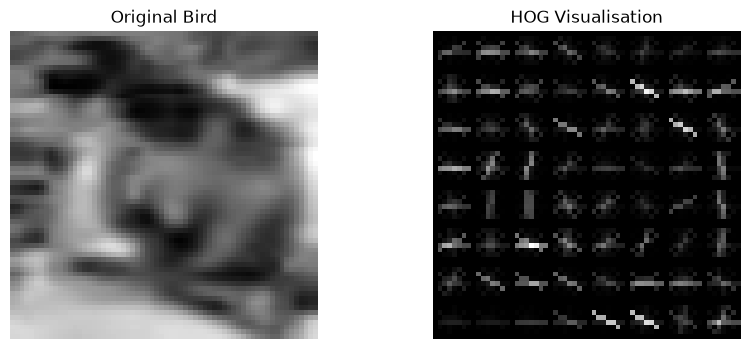

In [20]:

from skimage.feature import hog
import matplotlib.pyplot as plt

# Select our first bird sample
sample = np.array(
    positive_samples[0].convert("L")
)

# Extract features and HOG visualisation
features, hog_image = hog(
    sample,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(sample, cmap="gray")
axes[0].set_title("Original Bird")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG Visualisation")

for ax in axes:
    ax.axis("off")

plt.show()


In [21]:

import numpy as np

# Extract HOG features from bird samples
positive_features = [
    extract_hog_features(patch)
    for patch in positive_samples
]

# Extract HOG features from background samples
negative_features = [
    extract_hog_features(patch)
    for patch in negative_samples
]

# Combine features into one matrix
X = np.array(positive_features + negative_features)

# Create corresponding labels
# 1 = Bird, 0 = Background
y = np.array(
    [1] * len(positive_features) +
    [0] * len(negative_features)
)

print("Feature matrix shape:", X.shape)
print("Label vector shape:", y.shape)
print("Bird samples:", sum(y == 1))
print("Background samples:", sum(y == 0))


Feature matrix shape: (12, 1764)
Label vector shape: (12,)
Bird samples: 6
Background samples: 6
